# A tour of lapbox

[FastF1](https://docs.fastf1.dev/) gives you the data; `lapbox` tells you what it means, and says so when it can't. This notebook runs the library on real sessions from top to bottom: two laps compared, a pair the library refuses, race pace with the fuel taken out, and tyre wear.

To run it yourself:

```bash
pip install "lapbox[plot]" kaleido jupyterlab
```

FastF1 downloads each session the first time (a minute or two for a qualifying session's telemetry) and keeps it in its cache: its default folder, or wherever `FASTF1_CACHE` points. The charts are saved as images with `kaleido` so they show on GitHub; drop the two `pio.renderers` lines for interactive ones.

**Where the data came from (18 October 2026).** F1's live-timing archive, which FastF1 downloads past sessions from, has been answering those downloads with *401 Unauthorized* since mid-October (FastF1 [issue #978](https://github.com/theOehrly/Fast-F1/issues/978) reports it for every user; the machine this ran on last downloaded on 14 October), and FastF1 3.8.3, the latest release, sends no credentials for them. So this notebook was run from a clean install of lapbox 0.1.0 with its three sessions taken from a FastF1 cache filled before then. With an empty cache it can't fetch them until that changes.

In [1]:
import fastf1
import plotly.io as pio

import lapbox
from lapbox.pace import LapCleaningPipeline, clean_air_ranking, true_pace_ranking
from lapbox.plot import channel_traces, track_dominance
from lapbox.telemetry import compare, delta_time, detect_frozen_stretches
from lapbox.tyres import TyreDegradationModel, compound_summary, stint_degradation

fastf1.set_log_level("ERROR")
pio.renderers.default = "png"  # images, so the notebook reads on GitHub
pio.renderers["png"].width = 1000
print("lapbox", lapbox.__version__, "| FastF1", fastf1.__version__)

lapbox 0.1.0 | FastF1 3.8.3


## 1. Two laps, matched by track position

FastF1's `Distance` is integrated from speed, so two laps of the same circuit disagree on their length and can start from slightly different points: compared at equal distances, one car's corner lines up with the other's straight. `compare` stretches one lap onto the other and slides it until the speed traces line up, then says how well that worked: `residual` is what is left between the two traces (km/h RMS), and above 15 the pair is refused (`matched` is False).

In [2]:
quali = fastf1.get_session(2025, "Silverstone", "Q")
quali.load(weather=False, messages=False)
ver = quali.laps.pick_drivers("VER").pick_fastest().get_telemetry()
nor = quali.laps.pick_drivers("NOR").pick_fastest().get_telemetry()

result = compare(ver, nor, driver_a="VER", driver_b="NOR")
print(f"matched: {result.matched} (residual {result.residual:.1f} km/h)")
print(f"gap at the line: {delta_time(result.aligned).iloc[-1]:+.3f} s, VER ahead")
gain = result.segments.loc[result.segments["time_delta"].idxmax()]
loss = result.segments.loc[result.segments["time_delta"].idxmin()]
print(f"VER gains most from {gain.start_distance:.0f} to {gain.end_distance:.0f} m: {gain.time_delta:+.3f} s")
print(f"VER loses most from {loss.start_distance:.0f} to {loss.end_distance:.0f} m: {loss.time_delta:+.3f} s")

matched: True (residual 5.1 km/h)
gap at the line: +0.118 s, VER ahead
VER gains most from 2957 to 4765 m: +0.202 s
VER loses most from 5348 to 5826 m: -0.117 s


The time gap takes its total from each lap's own clock, so it ends exactly at the official lap-time gap; in between, at the official sector lines, it was a median 12–65 ms off over 19 qualifying sessions. Gains and losses are read between the lap's speed peaks (`segments`), where a few metres of misplacement cost almost nothing.

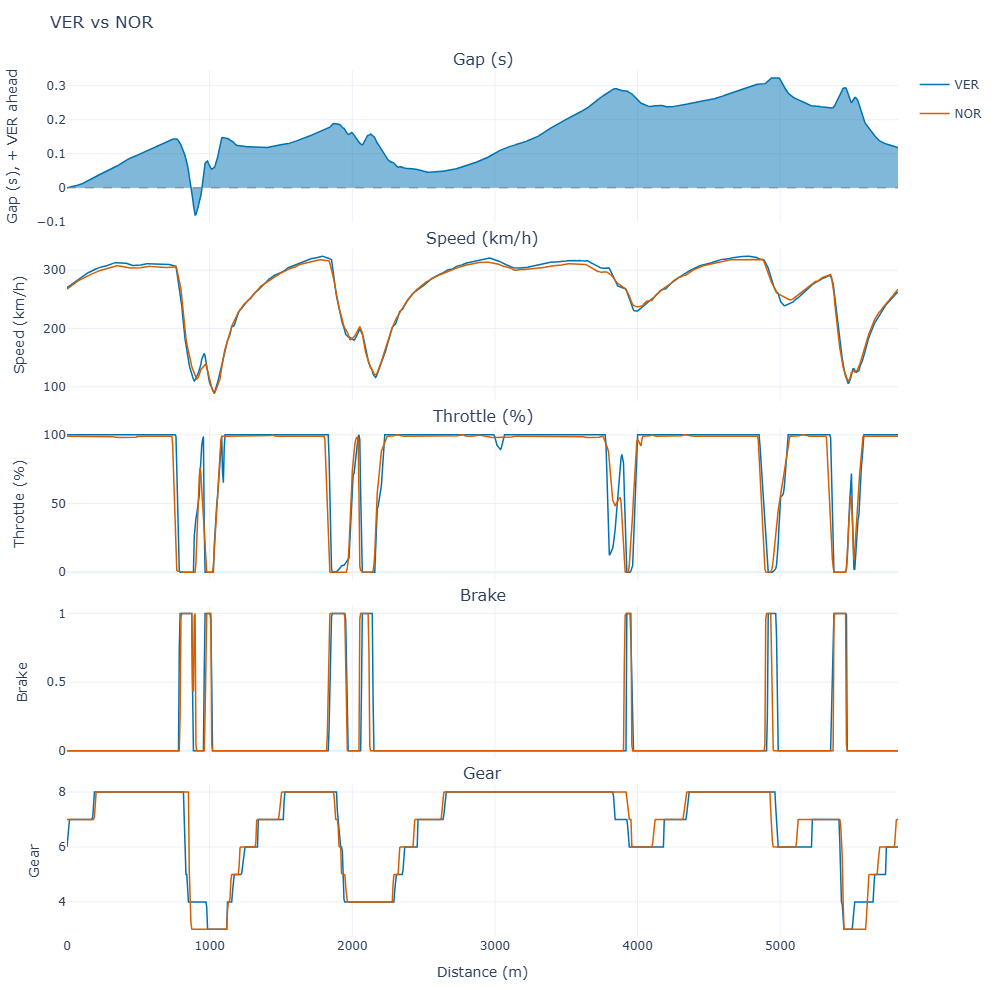

In [3]:
result.plot(channels=["Speed", "Throttle", "Brake", "nGear"])

The track map colours each minisector by who spent less time in it; grey ones were decided by less than 20 ms, too close to call. "More minisectors" is a count, not who was quicker: a driver can lose most minisectors and still take pole.

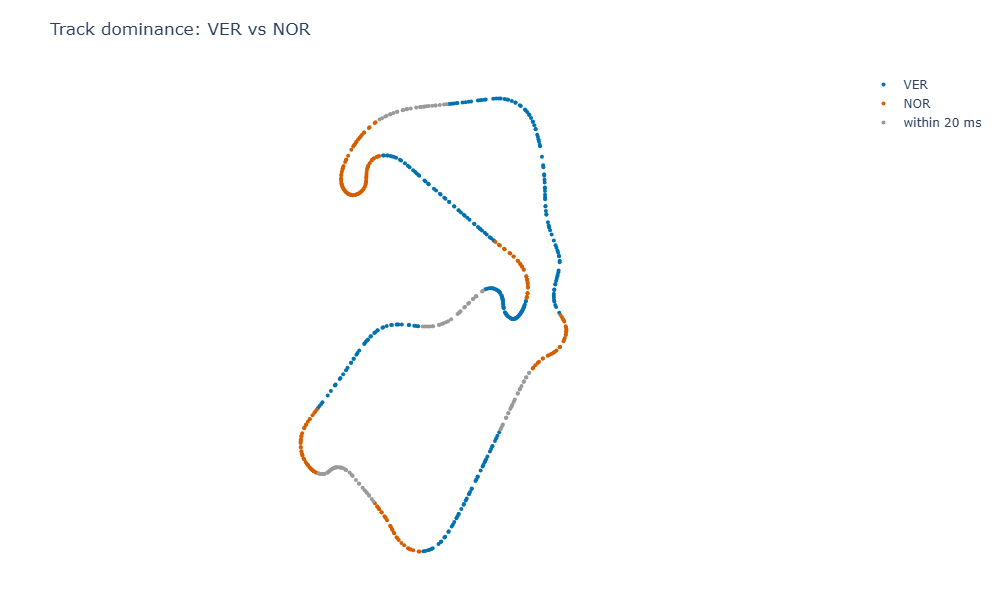

In [4]:
track_dominance(result, ver)

## 2. A pair the library refuses

On some 2026 laps the timing feed froze the car data: one reading repeated for a second or more while the car drove on. Distance is worked out from speed, so the rest of the lap is misplaced and no alignment can match it. `compare` doesn't hide that: `matched` is False, and the charts leave out everything that would compare the two laps point by point.

In [5]:
china = fastf1.get_session(2026, "China", "Q")
china.load(weather=False, messages=False)
alb = china.laps.pick_drivers("ALB").pick_fastest().get_telemetry()
bot = china.laps.pick_drivers("BOT").pick_fastest().get_telemetry()

refused = compare(alb, bot, driver_a="ALB", driver_b="BOT")
print(f"matched: {refused.matched} (residual {refused.residual:.1f} km/h, the limit is 15)")
detect_frozen_stretches(bot)

matched: False (residual 57.4 km/h, the limit is 15)


,start_distance,end_distance,seconds,speed,sentinel
0,2.603333,194.362500,3.241,213.0,True
1,5189.413056,5257.271111,1.279,191.0,True


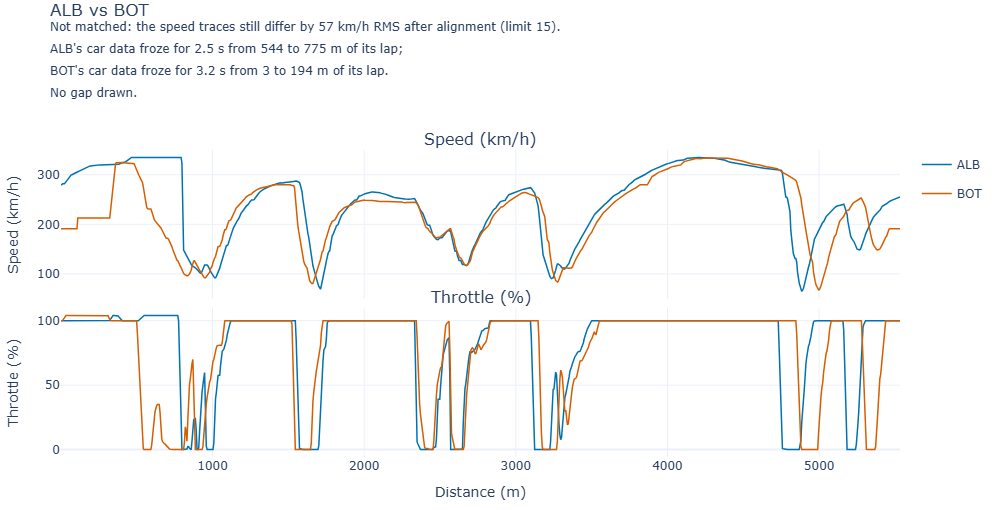

In [6]:
refused.plot(channels=["Speed", "Throttle"])

Each lap on its own is still worth reading. Its frozen stretch is shaded:

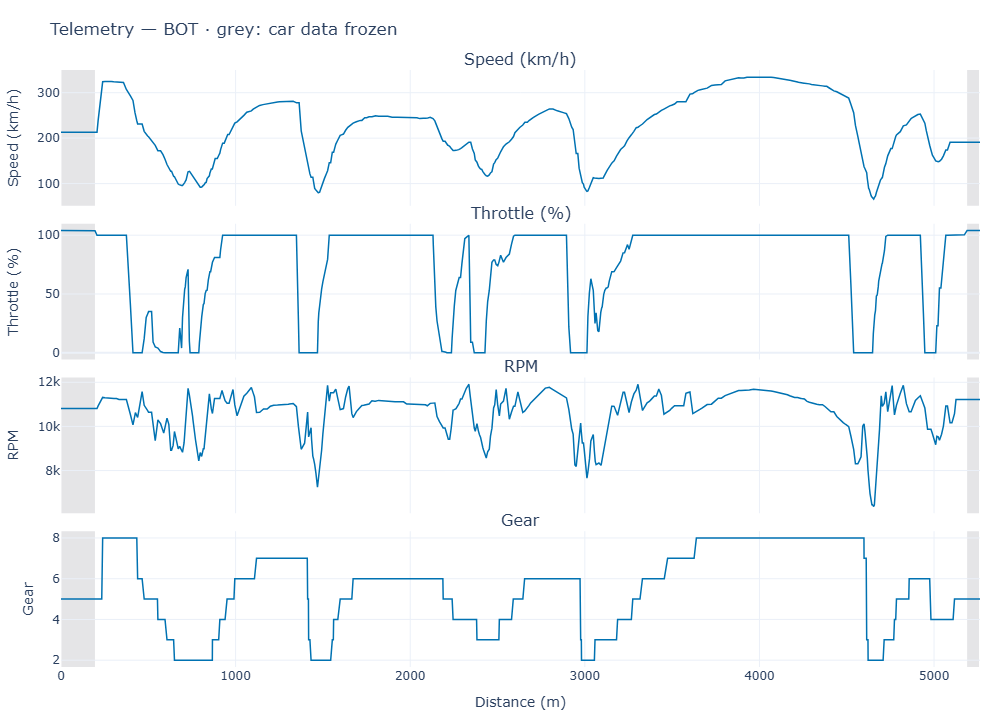

In [7]:
channel_traces(bot, channels=["Speed", "Throttle", "RPM", "nGear"], driver="BOT")

## 3. Race pace, with the fuel taken out

A car gets roughly two seconds a lap quicker over a Grand Prix just by burning fuel. `true_pace_ranking` takes the fuel still on board off every lap (an assumed 0.048 s per lap, the same for every car) and ranks each driver's median over their representative laps: from lap 2, no pit laps, within 107 % of their best. `clean_air_ranking` splits those laps by the gap to the car ahead at the line (2 s or less is traffic).

In [8]:
race = fastf1.get_session(2025, "Monza", "R")
race.load(telemetry=False, weather=False, messages=False)

pace = true_pace_ranking(race.laps)
pace[["driver", "corrected_median", "gap", "raw_rank", "corrected_rank"]].head(10).round(3)

,driver,corrected_median,gap,raw_rank,corrected_rank
0,VER,81.215,0.000,1,1
1,NOR,81.560,0.345,3,2
2,PIA,81.651,0.436,2,3
3,LEC,81.803,0.588,4,4
4,RUS,81.892,0.677,5,5
5,HAM,81.947,0.732,7,6
6,ANT,82.234,1.019,10,7
7,ALB,82.264,1.049,9,8
8,BEA,82.319,1.104,6,9
9,BOR,82.348,1.133,8,10


In [9]:
traffic = clean_air_ranking(race.laps)
traffic[["driver", "clean_pace", "traffic_pace", "delta", "traffic_share"]].head(5).round(3)

,driver,clean_pace,traffic_pace,delta,traffic_share
0,LAW,82.109,82.756,0.647,80.0
1,ALB,81.953,82.496,0.542,52.0
2,PIA,81.643,82.134,0.492,16.0
3,HAD,82.104,82.584,0.481,52.0
4,ANT,82.006,82.484,0.478,48.0


On raw medians PIA was second and NOR third; with the fuel taken out they swap, and the corrected top five matches the finishing order. LAW ran 80 % of his representative laps within 2 s of the car ahead and was 0.65 s a lap slower there. One race proves nothing about the method, and the 2 s threshold is a convention, not a measurement.

## 4. Tyres

Two answers to how fast each compound wore. `stint_degradation` fits a slope through each stint's fuel-corrected laps, and `compound_summary` takes the median per compound. `TyreDegradationModel` fits one line per compound over every driver, on laps within 107 % of each driver's best, with the same fuel effect taken off.

In [10]:
stints = stint_degradation(race.laps)
compound_summary(stints).round(3)

,compound,stints,laps,median_deg,best_deg,worst_deg
0,SOFT,3,20,-0.039,-0.149,0.043
1,MEDIUM,15,404,-0.001,-0.091,0.024
2,HARD,16,489,0.005,-0.026,0.061


In [11]:
model = TyreDegradationModel().fit(LapCleaningPipeline().run(race.laps))
model.summary()[["compound", "degradation_s_per_lap", "r2", "laps"]].round(3)

,compound,degradation_s_per_lap,r2,laps
0,SOFT,-0.133,0.173,24
1,MEDIUM,-0.008,0.021,399
2,HARD,0.014,0.067,491


Monza barely wears tyres. Both methods say the soft got *quicker* with age, on 20–24 laps, and the model's `r2` of 0.02–0.17 says tyre age explains little of how the lap times varied here. Neither number is the tyre alone: track evolution, the fuel assumption and who ran which stint are in it too. Read every rate with its laps.

Every function, and every limit the library has measured, is in the [Readme](../Readme.md).